# Projet Data Science en nutrition humaine 

Les étapes d’un tel projet sont les suivantes : 
1. Formuler le problème scientifique dans un langage clair et facilement compréhensible. 
Donner des exemples de questions auxquelles ce projet peut répondre. 
2. Identifier les données disponibles. 
a. Évaluer leur volumétrie et leur qualité.  
b. Établir pour chaque jeu de données une fiche d’identification.  
c. Choisir les jeux de données qui seront utilisés pour le projet. 
3. Data engineering :  
a. Charger,  nettoyer,  explorer  et  visualiser  les  données  ;  les  organiser  dans  un 
modèle relationnel 
b. Gestion des valeurs manquantes 
c. Représentativité de l’échantillon et pondérations d’enquête 
d. Confidentialité (RGPD, données pseudonymisées) 
e. Biais de sélection et de déclaration (par exemple sous-déclaration des apports) 
4. Proposer  des  indicateurs  ainsi  que  les  méthodes  statistiques  ou  d’apprentissage 
automatique (ML) permettant de répondre aux questions identifiées à la première étape.  
5. Présenter les résultats et leur interprétation. 
6. Donner des arguments pour justifier 
a. Le choix des métriques 
b. La validation des méthodes choisies et la robustesse des résultats 
c. La reproductibilité du pipeline 
d. La traçabilité des données

## 1. Objectif :
**« Comment se caractérisent les consommations alimentaires et les apports 
nutritionnels de la population française, comment varient-ils selon l’âge et le sexe, et quels 
aliments y contribuent le plus ? »**  

Cette analyse permettra de répondre, par exemple, aux questions suivantes : 
- Quels sont les apports énergétiques moyens ?  
- Comment varient-ils selon l'âge et le sexe ?  
- Quels aliments contribuent le plus aux apports en protéines, calcium, fer, fibres, etc. ?  
- Quelle est la variabilité interindividuelle ?  
- Existe-t-il différents profils alimentaires ?  
- Comment comparer plusieurs enquêtes alimentaires ?  

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats



## 2. La pipeline_Data Engineering

### a. Traitement des csv disponibles

**Regler le prbl des individus présent uniquement dans certaines tables :**  
On a 5855 individus dans `description-indiv.csv` initiallement, mais uniquement 4013 individus commun à toutes les tables. On en conserve donc une grosse parti et on va donc traiter les données uniquemens sur les lignes en commun (ca devrait enlever des cas compliqués sur des na ...)

In [5]:
def fusionner_apports(dfs, d_app):
    """
    Ajoute les colonnes de d_app à chaque DataFrame du dictionnaire dfs (clé NOIND).
    On garde les lignes de dfs (left) : pas de suppression d'individus.
    Les colonnes de d_app déjà présentes dans dfs sont ignorées (sauf NOIND).
    """
    resultat = {}
    for nom, data in dfs.items():
        colonnes_nouvelles = [c for c in d_app.columns if c == "NOIND" or c not in data.columns]
        resultat[nom] = data.merge(d_app[colonnes_nouvelles], on="NOIND", how="left")
    return resultat

In [6]:
%load_ext autoreload
%autoreload 2

from nettoyage import nettoyer_tout, plot_age_distribution, plot_diff_na

dfs_na, dfs_imp, resume, journal, non_imputees = nettoyer_tout("tables")
resume

d_app = pd.read_csv("tables/apports-nut-alim.csv", sep=";")

dfs_na = fusionner_apports(dfs_na, d_app)
dfs_imp = fusionner_apports(dfs_imp, d_app)

print(dfs_na["Adultes"].shape, dfs_imp["Adultes"].shape)
print(dfs_na["Enfants"].shape, dfs_imp["Enfants"].shape)
print(dfs_na["Nourrissons"].shape, dfs_imp["Nourrissons"].shape)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
(2121, 274) (2054, 274)
(1808, 263) (1728, 263)
(185, 214) (180, 214)


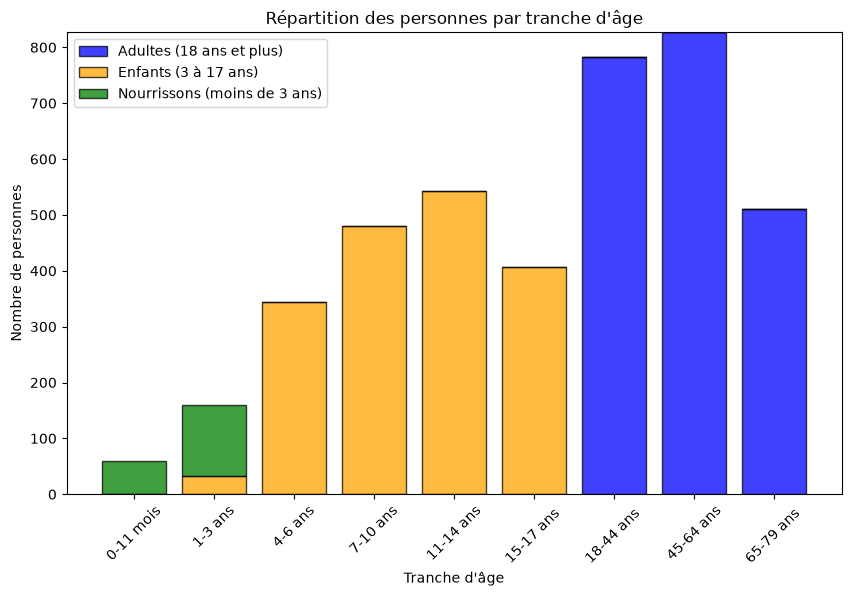

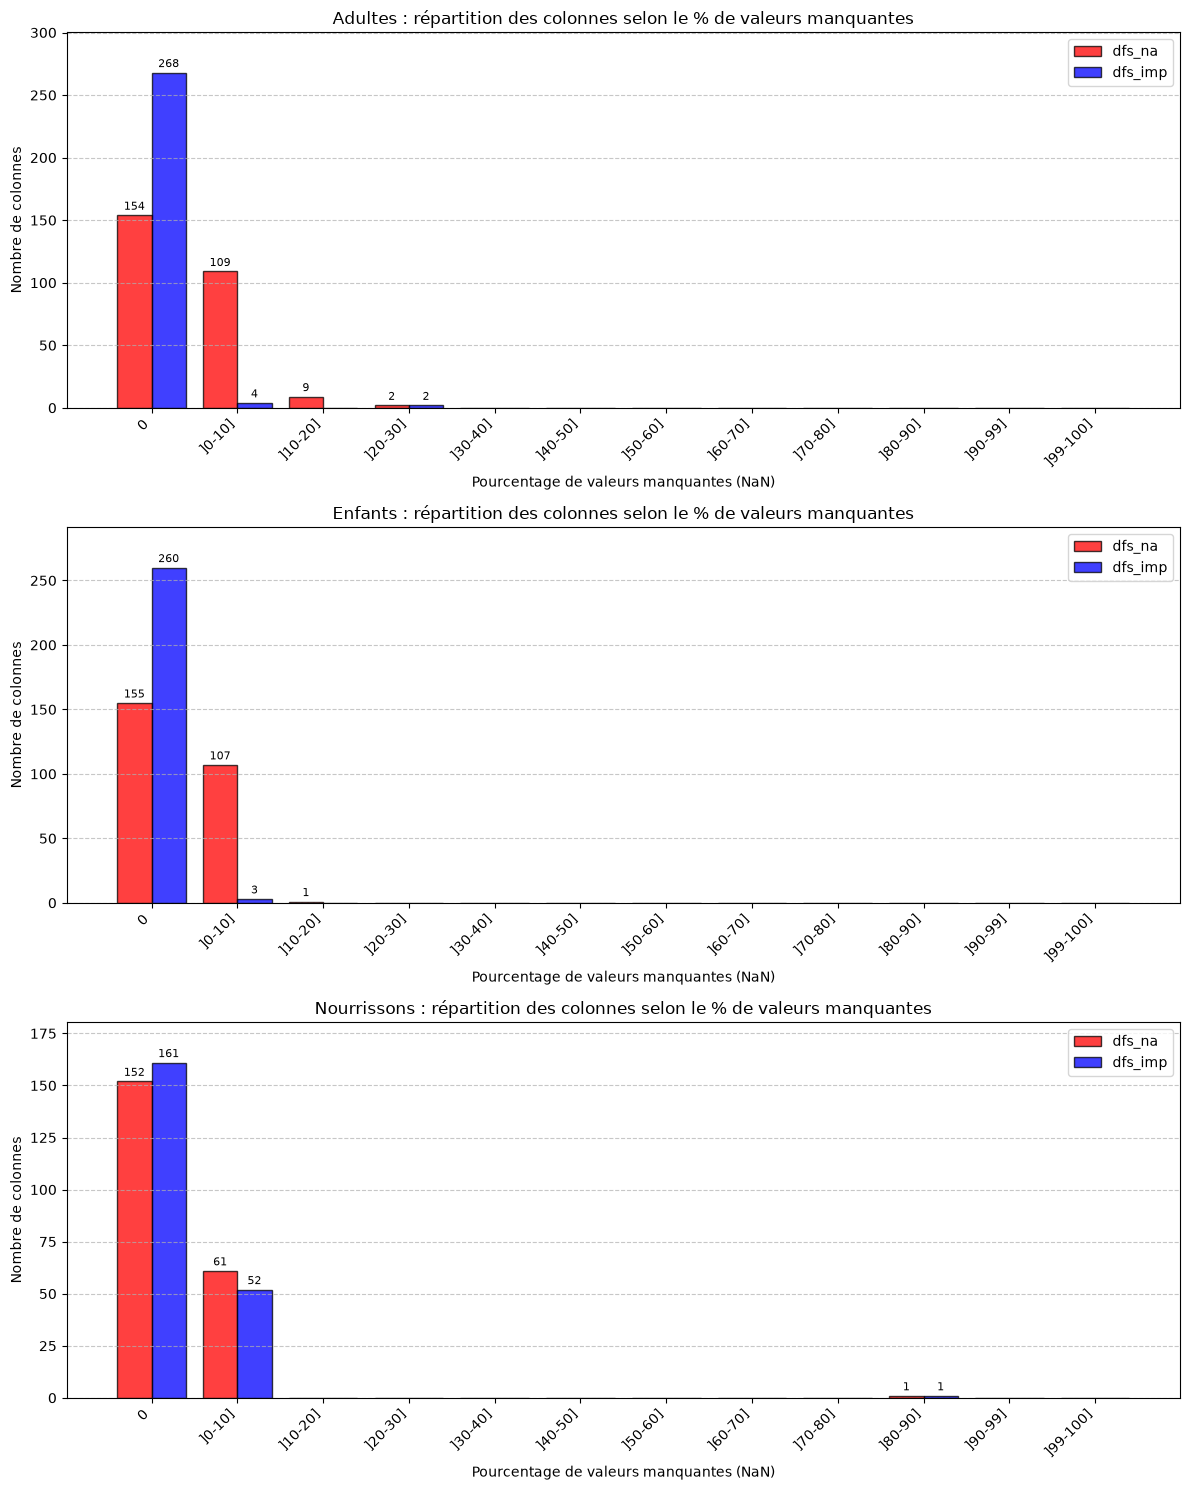

In [7]:
plot_age_distribution(dfs_na)

plot_diff_na(dfs_na, "dfs_na", dfs_imp, "dfs_imp")

**Etude de Apports_nut_alim**

Cette table fournit les apports nutritionnels individuels journaliers estimés à partir des consommées observées sur 2 ou 3 jours de rappels de 24 heures pour les 4 114 individus de la Pop3, ainsi que la contribution à l’Apport Energétique Sans Alcool (AESA) pour les macronutriments et les apports pour 100 kcal pour les vitamines et minéraux.  

Ici la table est jointe à d_descri dans le dataframe df. Comme vu dans la partie précédente, pour les nourissons il y a pour toutes les colonnes contrib des nan (3.67%). Ceci s'explique par le fait que les données des colonnes nutriments sont égaux à 0. 

--> il faut donc supprimer ces lignes.

In [8]:
prefixes = ("nutriment", "contribution")

for dfs in (dfs_na, dfs_imp):
    for nom, data in dfs.items():
        cols = [c for c in data.columns if c.lower().startswith(prefixes)]
        masque_nul = data[cols].sum(axis=1) == 0
        print(f"{nom} : {len(cols)} colonnes testées, {masque_nul.sum()} ligne(s) à somme nulle")
        dfs[nom] = data[~masque_nul].copy()

print(dfs_na["Adultes"].shape, dfs_imp["Adultes"].shape)
print(dfs_na["Enfants"].shape, dfs_imp["Enfants"].shape)
print(dfs_na["Nourrissons"].shape, dfs_imp["Nourrissons"].shape)

Adultes : 54 colonnes testées, 0 ligne(s) à somme nulle
Enfants : 54 colonnes testées, 0 ligne(s) à somme nulle
Nourrissons : 54 colonnes testées, 7 ligne(s) à somme nulle
Adultes : 54 colonnes testées, 0 ligne(s) à somme nulle
Enfants : 54 colonnes testées, 0 ligne(s) à somme nulle
Nourrissons : 54 colonnes testées, 7 ligne(s) à somme nulle
(2121, 274) (2054, 274)
(1808, 263) (1728, 263)
(178, 214) (173, 214)


### b. Retrouver les apports par personnes

Il faut recalculer les apports journaliers de la population 3 (4113) à partir du fichier `conso-compo-alim-vf-mad-datagouv2021.csv`

In [9]:
d_conso = pd.read_csv("tables/conso-compo-alim-vf-mad-datagouv2021.csv", sep=";")

print("CONSO_COMPO_ALIM :", d_conso.shape, "(attendu : 256 301 lignes x 109 colonnes)")
print("APPORTS_NUT_ALIM :", d_app.shape, "(attendu : 4 114 lignes x 108 colonnes)")

CONSO_COMPO_ALIM : (256301, 109) (attendu : 256 301 lignes x 109 colonnes)
APPORTS_NUT_ALIM : (4114, 108) (attendu : 4 114 lignes x 108 colonnes)


C:\Users\bimms\AppData\Local\Temp\ipykernel_26992\4114004924.py:1: DtypeWarning: Columns (19: facette_01, 31: facette_07, 51: facette_25) have mixed types. Specify dtype option on import or set low_memory=False.
  d_conso = pd.read_csv("tables/conso-compo-alim-vf-mad-datagouv2021.csv", sep=";")


**Correspondance nutriments : table source ↔ table officielle**

Dans `APPORTS_NUT_ALIM`, les nutriments sont nommés `nutriment1` à `nutriment54` (p. 78-80). Dans `CONSO_COMPO_ALIM`, ils ont des noms explicites (p. 72-74), dans le **même ordre**. Le dictionnaire ci-dessous fait le lien : c'est lui qui permet de comparer colonne à colonne à la fin.

Les unités sont conservées : si la teneur est en mg/100 g, l'apport sera en mg/j (ex. EPA, DHA, acide arachidonique en mg ; rétinol, vitamine B9 en µg ; énergie en kcal).

In [10]:
NUTRIMENTS = [
    "aet", "aesa", "proteines", "glucides", "sucres", "amidon", "polyols", "fibres",
    "acides_organiques", "lipides", "ags", "ag_16_0", "ag_18_0", "ag_14_0", "ag_12_0",
    "ag_10_0", "ag_04_0", "ag_06_0", "ag_08_0", "agmi", "ag_18_1_ole", "agpi",
    "ag_18_2_lino", "ag_18_3_a_lino", "ag_20_4_ara", "ag_20_5_epa", "ag_20_6_dha",
    "alcool", "eau", "sodium", "sel", "magnesium", "phosphore", "potassium", "calcium",
    "manganese", "fer", "cuivre", "zinc", "selenium", "iode", "retinol", "beta_carotene",
    "vitamine_b1", "vitamine_b2", "vitamine_b3", "vitamine_b5", "vitamine_b6",
    "vitamine_b9", "vitamine_b12", "vitamine_c", "vitamine_d", "vitamine_e", "vitamine_k2",
]

# {"nutriment1": "aet", "nutriment2": "aesa", ...}
MAPPING = {f"nutriment{i}": nom for i, nom in enumerate(NUTRIMENTS, start=1)}

**Étape 1 : ne garder que les colonnes utiles**

Les facettes (`facette_01` … `facette_27` et leurs libellés), les libellés d'aliments, les lieux, etc. ne servent pas au calcul des apports. On garde :

- `NOIND` : identifiant de l'individu ;
- `R24_num` : numéro du rappel de 24 h (1, 2 ou 3) → avec `NOIND`, identifie une **journée** ;
- `R24_nombre` : nombre de rappels de l'individu (2 ou 3) ;
- `R24_pond` : pondération du rappel (semaine vs week-end + jours fériés) ;
- `qte_conso` : quantité consommée en g (**brute**, voir étape 1) ;
- les 54 colonnes de nutriments (teneurs pour 100 g).

In [11]:
colonnes_utiles = ["NOIND", "R24_num", "R24_nombre", "R24_pond", "qte_conso"] + NUTRIMENTS
d_conso = d_conso[colonnes_utiles]

# NOIND est un identifiant "caractère" : on le nettoie pour que les jointures fonctionnent
d_conso["NOIND"] = d_conso["NOIND"].astype(str).str.strip()

print(d_conso.shape)
d_conso.head()

(256301, 59)


,NOIND,R24_num,R24_nombre,R24_pond,qte_conso,aet,aesa,proteines,glucides,sucres,...,vitamine_b2,vitamine_b3,vitamine_b5,vitamine_b6,vitamine_b9,vitamine_b12,vitamine_c,vitamine_d,vitamine_e,vitamine_k2
0,110100101,1,3,1.0,147.50,0.0,0.000000,0.00,0.00,0.00,...,0.000,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0
1,110100101,1,3,1.0,500.00,45.0,45.009998,0.61,9.58,9.58,...,0.023,0.30,0.24,0.10,30.0,0.00,24.70,0.00,0.20,0.0
2,110100101,1,3,1.0,3.22,0.0,0.000000,0.00,0.00,0.00,...,0.000,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0
3,110100101,1,3,1.0,107.00,267.0,267.620000,3.28,34.90,0.57,...,0.059,2.57,0.43,0.37,32.3,0.04,19.00,0.00,0.44,0.0
4,110100101,1,3,1.0,161.00,234.0,234.100010,12.00,19.30,1.00,...,0.180,6.44,0.95,0.47,7.0,0.43,0.75,0.25,0.27,20.0


**Étape 2 : apport de chaque ligne de consommation**

Pour chaque aliment consommé et chaque nutriment :

$$\text{apport} = \frac{\text{qte\_conso} \times \text{teneur pour 100 g}}{100}$$

**Pourquoi `qte_conso` et pas `qte_conso_pond` ?** Ici on ne choisi qte_conso, l'objectif serait de pondérer lors du moyennage par jour et pas avant.

In [12]:
apports = d_conso.copy()

# .mul(..., axis=0) multiplie chaque colonne de nutriment par qte_conso, ligne à ligne
apports[NUTRIMENTS] = d_conso[NUTRIMENTS].mul(d_conso["qte_conso"], axis=0) / 100

# Contrôle sur un exemple : 100 g d'un aliment à 10 g de protéines/100 g -> 10 g de protéines
apports[["NOIND", "R24_num", "qte_conso", "proteines", "lipides", "aet"]].head()

,NOIND,R24_num,qte_conso,proteines,lipides,aet
0,110100101,1,147.50,0.0000,0.000,0.00
1,110100101,1,500.00,3.0500,0.550,225.00
2,110100101,1,3.22,0.0000,0.000,0.00
3,110100101,1,107.00,3.5096,12.733,285.69
4,110100101,1,161.00,19.3200,19.481,376.74


**Étape 3 : somme des apports sur une journée**

Une journée = un rappel de 24 h = un couple `(NOIND, R24_num)`. On additionne tous les aliments consommés ce jour-là.

Deux contrôles :
- on doit retrouver **12 210 journées** (p. 66 de la notice) ;
- `R24_pond` doit être **constant au sein d'une journée** (c'est une pondération de journée), on le conserve donc avec `first`.

`sum(min_count=1)` : si toutes les teneurs d'un nutriment sont manquantes sur la journée, le résultat est `NaN` et non 0, ce qui permet de repérer les trous de composition.

In [13]:
groupes = apports.groupby(["NOIND", "R24_num"], sort=False)

# Somme des apports de la journée
journees = groupes[NUTRIMENTS].sum(min_count=1)

# On récupère aussi R24_nombre et R24_pond (identiques sur toutes les lignes de la journée)
journees["R24_nombre"] = groupes["R24_nombre"].first()
journees["R24_pond"]   = groupes["R24_pond"].first()
journees = journees.reset_index()

print("Nombre de journées reconstituées :", len(journees), "(attendu : 12 210)")
print("Journées avec R24_pond non constant :", (groupes["R24_pond"].nunique() > 1).sum(), "(attendu : 0)")
journees.head()

Nombre de journées reconstituées : 12210 (attendu : 12 210)
Journées avec R24_pond non constant : 0 (attendu : 0)


,NOIND,R24_num,aet,aesa,proteines,glucides,sucres,amidon,polyols,fibres,...,vitamine_b5,vitamine_b6,vitamine_b9,vitamine_b12,vitamine_c,vitamine_d,vitamine_e,vitamine_k2,R24_nombre,R24_pond
0,110100101,1,2001.385429,2001.151092,61.214919,300.497295,114.865990,142.475174,0.113750,16.680314,...,5.807785,2.069897,320.612657,2.306014,157.977467,0.777500,3.983454,34.419137,3,1.000000
1,110100101,2,1773.946694,1772.814157,86.521113,262.122523,153.173482,91.793729,0.095100,17.513164,...,7.670150,2.406031,408.626021,6.155734,210.282213,3.505624,6.104520,9.791000,3,1.000000
2,110100101,3,2457.955339,2457.873602,101.428869,299.761551,168.321265,119.884409,0.607900,15.124732,...,8.047475,2.411510,299.164384,4.998121,170.325895,2.329679,5.997709,34.756802,3,1.000000
3,110100701,1,1164.132765,1164.521748,40.099867,151.508114,92.911415,45.465498,0.864000,21.400009,...,4.237213,1.223764,338.595064,1.725769,297.805460,2.450162,9.712676,1.296000,3,1.071428
4,110100701,2,1393.405317,1389.406534,50.617045,158.414836,101.506255,47.739116,2.819725,28.777203,...,3.826478,1.111080,331.928213,1.513100,330.748207,4.013300,9.111545,0.994000,3,0.857143


**Étape 4 : moyenne des journées, pondérée, par individu**

La notice ne détaille pas la formule exacte de l'ANSES. On calcule donc **deux variantes** et on laissera la comparaison trancher :

- **A** : moyenne pondérée sur les jours *présents* dans la table : $\dfrac{\sum_j w_j \, x_j}{\sum_j w_j}$
- **B** : moyenne simple, **sans pondération** (témoin).

Ici les valeurs `NaN` sont comptées comme 0 (hypothèse à garder en tête si des écarts apparaissent sur certains nutriments).

In [14]:
w = journees["R24_pond"]
par_individu = journees.groupby("NOIND")

# Numérateur : somme sur les jours de (apport du jour x poids du jour)
somme_ponderee = journees[NUTRIMENTS].fillna(0).mul(w, axis=0).groupby(journees["NOIND"]).sum()

somme_poids = w.groupby(journees["NOIND"]).sum()          # dénominateur de A
nb_rappels  = par_individu["R24_nombre"].first()           # dénominateur de B et C

variante_A = somme_ponderee.div(somme_poids, axis=0)
variante_B = journees[NUTRIMENTS].fillna(0).groupby(journees["NOIND"]).sum().div(nb_rappels, axis=0)

variantes = {"A (pondéré, jours présents)": variante_A,
             "B (pondéré, / R24_nombre)":   variante_B}

print("Individus reconstitués :", len(variante_A))
variante_A[["aet", "proteines", "lipides", "glucides"]].head()

Individus reconstitués : 4114


,aet,proteines,lipides,glucides
NOIND,,,,
110100101,2077.762487,83.054967,59.857980,287.460457
110100701,1123.739511,42.008882,36.630998,141.191613
110100801,2544.575378,87.255278,106.429591,292.853629
110101201,2154.636808,64.621907,82.042803,176.348305
110101401,1229.299356,44.161503,53.178930,134.016301


**Comparaison avec `APPORTS_NUT_ALIM`**

On renomme les colonnes recalculées (`aet` → `nutriment1`, etc.) grâce à `MAPPING`, on aligne les individus sur `NOIND`, puis pour chaque nutriment on calcule :

- `max_abs_diff` : plus grand écart absolu ;
- `mean_rel_diff` : écart relatif moyen (hors valeurs officielles nulles) ;
- `pct_hors_tol` : % d'individus dont l'écart relatif dépasse la tolérance ;
- `corr` : corrélation entre valeurs recalculées et officielles.

In [15]:
officiel = d_app.copy()
officiel["NOIND"] = officiel["NOIND"].astype(str).str.strip()
officiel = officiel.set_index("NOIND")


def comparer(recalcule, officiel, tolerance=1e-4):
    """Compare un DataFrame recalculé (index NOIND, colonnes = noms de nutriments)
    à la table officielle (colonnes nutriment1..54). Retourne un tableau par nutriment."""
    rec = recalcule.rename(columns={nom: cle for cle, nom in MAPPING.items()})
    communs = rec.index.intersection(officiel.index)
    lignes = []
    for cle, nom in MAPPING.items():
        a, b = rec.loc[communs, cle], officiel.loc[communs, cle]
        ecart = (a - b).abs()
        relatif = ecart / b.abs().replace(0, np.nan)
        lignes.append({
            "nutriment": cle, "colonne": nom,
            "max_abs_diff": ecart.max(),
            "mean_rel_diff": relatif.mean(),
            "pct_hors_tol": (relatif > tolerance).mean() * 100,
            "corr": a.corr(b),
        })
    return pd.DataFrame(lignes), len(communs)


resultats = {}
for nom, df in variantes.items():
    tableau, n_communs = comparer(df, officiel)
    resultats[nom] = tableau
    print(f"Variante {nom} : {n_communs} individus communs, "
          f"écart relatif moyen tous nutriments = {tableau['mean_rel_diff'].mean():.3g}")

Variante A (pondéré, jours présents) : 4114 individus communs, écart relatif moyen tous nutriments = 3.26e-08
Variante B (pondéré, / R24_nombre) : 4114 individus communs, écart relatif moyen tous nutriments = 0.0372


**Conclusion** 

On a bien réussi à retrouver les résultats de apports :) 

Cependant, j'ai recréé que les résultats des colonnes nutriments car la documentation n'explicite pas les calculs des colonnes contrib de 1 à 54. Donc on va garder le csv apport.

---
---

## Questions :

Pour chacune des questions suivantes, préciser l’indicateur, la méthode et la visualisation
retenus :

**Q1 — Apports énergétiques :**
Quelle est la distribution de l'apport énergétique journalier ?  

Comme dit précédemment, il faut étudier séparement enfants et adultes. Par ailleurs, dans les études d'apports il n'y a que la population 3. Pour analyser la distribution de l'apport énergétique journalier au sein de la population, il faut pondérer les individus en fonction de leur pondération individuele `pond_indiv_adu_pop3` ou `pond_indiv_adu_pop3` trouvable dans le csv `d_descri` et donc dans les csv `df_adulte`, `df_enfant` et `df_nourisson`.  
Par ailleurs, l'apport énergétique correspond à la colonne `nutriment1`.

In [16]:
# Renommer les df 
df_adulte = dfs_na["Adultes"]
df_enfant = dfs_na["Enfants"]
df_nourisson = dfs_na["Nourrissons"]

# Listes des fonctions calculant les statistiques pondérées des populations

def quantile_pondere(y, w, q):
    """Quantile(s) pondéré(s) par interpolation de la fonction de répartition pondérée.
        avec :  - y : la liste des valeurs d'une variable de chaque individu,
                - w : le poids de chaque individu,
                - q : la liste des quantiles à calculer
    """
    ordre = np.argsort(y)
    y_s, w_s = np.asarray(y)[ordre], np.asarray(w)[ordre]
    cum = (np.cumsum(w_s) - 0.5 * w_s) / w_s.sum()
    return np.interp(q, cum, y_s)



def ic95_moyenne_plan_sondage(d, var, pond):
    """
    Calcule la moyenne pondérée et son intervalle de confiance à 95 %
    en tenant compte du plan de sondage par linéarisation.
        avec :  - d : Tableau contenant les observations,
                - var : Nom de la variable dont on veut estimer la moyenne,
                - pond : Nom de la colonne contenant les poids de sondage
    """
    y = d[var].to_numpy(dtype=float)
    w = d[pond].to_numpy(dtype=float)

    # Calcule la moyenne pondérée :
    moy = np.average(y, weights=w)
    # Tableau intermédiaire pour le calcul de variance. z = poids × (valeur observée - moyenne estimée).
    z = pd.DataFrame({
        "strate": d["strate"].to_numpy(),
        "zae": d["zae"].to_numpy(),
        "z": w * (y - moy)
    })

    # Obtenir une contribution totale par grappe.
    tot_grappe = z.groupby(["strate", "zae"])["z"].sum().reset_index()

    var_tot = 0.0
    n_grappes = 0
    n_strates = 0
    for _, g in tot_grappe.groupby("strate"):
        n_h = len(g)
        if n_h > 1:
            var_tot += n_h / (n_h - 1)* ((g["z"] - g["z"].mean()) ** 2).sum()
            n_grappes += n_h
            n_strates += 1

    se = np.sqrt(var_tot) / w.sum()         # Calculer l'erreur standard de la moyenne pondérée.    
    ddl = max(n_grappes - n_strates, 1)     # Calcule les degrés de liberté approximatifs.
    t = stats.t.ppf(0.975, ddl)             # Obtenir le quantile à 97,5 % de la loi de Student.

    # Calculer les bornes de l'intervalle de confiance à 95 %.
    borne_inf = moy - t * se
    borne_sup = moy + t * se

    return moy, se, borne_inf, borne_sup



def stats_descriptives_ponderees(d, var, pond):
    d = d.dropna(subset=[var, pond, "strate", "zae"])
    d = d[d[pond] > 0]
    y, w = d[var].to_numpy(float), d[pond].to_numpy(float)

    moy, se, ic_inf, ic_sup = ic95_moyenne_plan_sondage(d, var, pond)
    ecart_type = np.sqrt(np.average((y - moy) ** 2, weights=w))
    med = quantile_pondere(y, w, [0.5])

    return {
        "n (non pondéré)": len(d),
        "Moyenne": moy,
        "IC95% inf": ic_inf,
        "IC95% sup": ic_sup,
        "Écart-type": ecart_type,
        "Min": y.min(),
        "Médiane": med[0],
        "Max": y.max(),
    }



In [17]:
VAR_E = "nutriment1"   # AET en kcal/j

groupes_q1 = {
    "Adultes (18-79 ans)":      (df_adulte,    "pond_indiv_adu_pop3", "tab:blue"),
    "Enfants (3-17 ans)":       (df_enfant,    "pond_indiv_enf_pop3", "tab:orange"),
    "Nourrissons (0-35 mois)":  (df_nourisson, "pond_indiv_enf_pop3", "tab:green"),
}


# ---------------- Tableau récapitulatif ----------------
tableau_q1 = pd.DataFrame({nom: stats_descriptives_ponderees(d, VAR_E, pond)for nom, (d, pond, _) in groupes_q1.items()}).T
print("Apport énergétique journalier (kcal/j) – statistiques pondérées")
display(tableau_q1.round(1))

Apport énergétique journalier (kcal/j) – statistiques pondérées


,n (non pondéré),Moyenne,IC95% inf,IC95% sup,Écart-type,Min,Médiane,Max
Adultes (18-79 ans),2121.0,2102.4,2053.9,2150.9,764.4,323.1,2014.2,5582.4
Enfants (3-17 ans),1808.0,1814.4,1765.3,1863.4,580.8,476.3,1740.6,5020.7
Nourrissons (0-35 mois),178.0,996.7,927.2,1066.1,333.0,0.0,996.5,2044.4


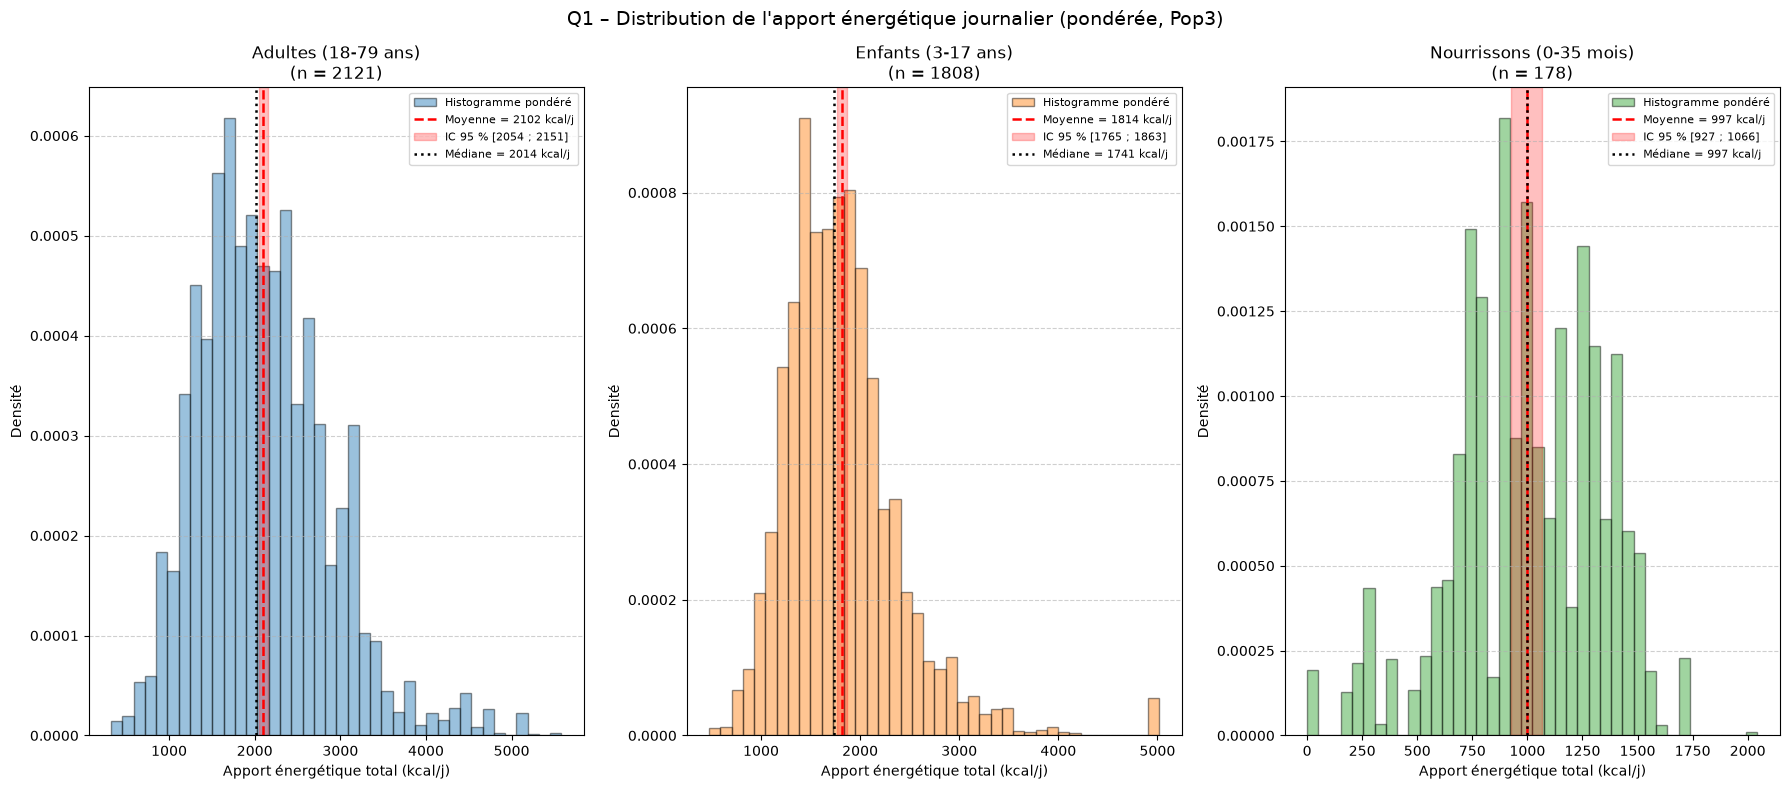

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax, (nom, (d, pond, couleur)) in zip(axes, groupes_q1.items()):
    d = d.dropna(subset=[VAR_E, pond])
    d = d[d[pond] > 0]
    y, w = d[VAR_E].to_numpy(float), d[pond].to_numpy(float)

    # histogramme pondéré (densité)
    ax.hist(y, bins=40, weights=w, density=True, color=couleur,
            alpha=0.45, edgecolor="black", label="Histogramme pondéré")

    # moyenne, IC 95 %, médiane
    s = tableau_q1.loc[nom]
    ax.axvline(s["Moyenne"], color="red", ls="--", lw=1.8,
               label=f"Moyenne = {s['Moyenne']:.0f} kcal/j")
    ax.axvspan(s["IC95% inf"], s["IC95% sup"], color="red", alpha=0.25,
               label=f"IC 95 % [{s['IC95% inf']:.0f} ; {s['IC95% sup']:.0f}]")
    ax.axvline(s["Médiane"], color="black", ls=":", lw=1.8,
               label=f"Médiane = {s['Médiane']:.0f} kcal/j")

    ax.set_title(f"{nom}\n(n = {int(s['n (non pondéré)'])})")
    ax.set_xlabel("Apport énergétique total (kcal/j)")
    ax.set_ylabel("Densité")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(fontsize=8)

fig.suptitle("Q1 – Distribution de l'apport énergétique journalier (pondérée, Pop3)", fontsize=14)
plt.tight_layout()
plt.show()

Chez les adultes, l’apport énergétique journalier moyen pondéré est de 2 107 kcal/j, contre 1 832 kcal/j chez les enfants et 1 086 kcal/j chez les nourrissons, ce qui traduit une augmentation des besoins énergétiques avec l’âge. Les distributions sont relativement concentrées autour de la moyenne chez les adultes et les enfants. Cependant chez les nourrissons, la distribution est plus dispersée relativement à la moyenne, traduisant une plus grande hétérogénéité des apports énergétiques au sein de cette population du aux très grandes différences d'alimentation entre yun nourisson de moins de 6 mois et de plus d'1 an et demi.

**Q2 — Sexe :**
Comment les apports nutritionnels diffèrent-ils selon le sexe ?  

Nous nous basons sur la même logique que la question 1 mais en séparant par sexe en plus de par âge.

In [19]:
df_ad_wm = df_adulte[df_adulte['sex_PS'] == 2].copy()
df_ad_m = df_adulte[df_adulte['sex_PS'] == 1].copy()
df_en_wm = df_enfant[df_enfant['sex_PS'] == 2].copy()
df_en_m = df_enfant[df_enfant['sex_PS'] == 1].copy()
df_nr_wm = df_nourisson[df_nourisson['sex_PS'] == 2].copy()
df_nr_m = df_nourisson[df_nourisson['sex_PS'] == 1].copy()



groupes_q2 = {
    "Adultes femme (18-79 ans)":      (df_ad_wm,    "pond_indiv_adu_pop3", "tab:blue"),
    "Adultes homme (18-79 ans)":      (df_ad_m,    "pond_indiv_adu_pop3", "tab:blue"),
    "Enfants femme (3-17 ans)":       (df_en_wm,    "pond_indiv_enf_pop3", "tab:orange"),
    "Enfants homme (3-17 ans)":       (df_en_m,    "pond_indiv_enf_pop3", "tab:orange"),
    "Nourrissons femme (0-35 mois)":  (df_nr_wm, "pond_indiv_enf_pop3", "tab:green"),
    "Nourrissons homme (0-35 mois)":  (df_nr_m, "pond_indiv_enf_pop3", "tab:green"),
}

tableau_q2 = pd.DataFrame({
    nom: stats_descriptives_ponderees(d, VAR_E, pond)
    for nom, (d, pond, _) in groupes_q2.items()
}).T
print("Apport énergétique journalier (kcal/j) – statistiques pondérées")
display(tableau_q2.round(1))

Apport énergétique journalier (kcal/j) – statistiques pondérées


,n (non pondéré),Moyenne,IC95% inf,IC95% sup,Écart-type,Min,Médiane,Max
Adultes femme (18-79 ans),1234.0,1787.0,1734.9,1839.1,580.8,323.1,1723.2,5582.4
Adultes homme (18-79 ans),887.0,2437.6,2355.9,2519.2,792.9,439.7,2385.9,5215.2
Enfants femme (3-17 ans),891.0,1697.3,1600.9,1793.8,590.6,476.3,1629.4,5020.7
Enfants homme (3-17 ans),917.0,1928.1,1888.1,1968.0,547.6,618.3,1852.6,4143.3
Nourrissons femme (0-35 mois),80.0,940.6,859.4,1021.9,316.7,160.3,900.6,1573.4
Nourrissons homme (0-35 mois),98.0,1047.0,946.8,1147.3,339.2,0.0,1083.6,2044.4


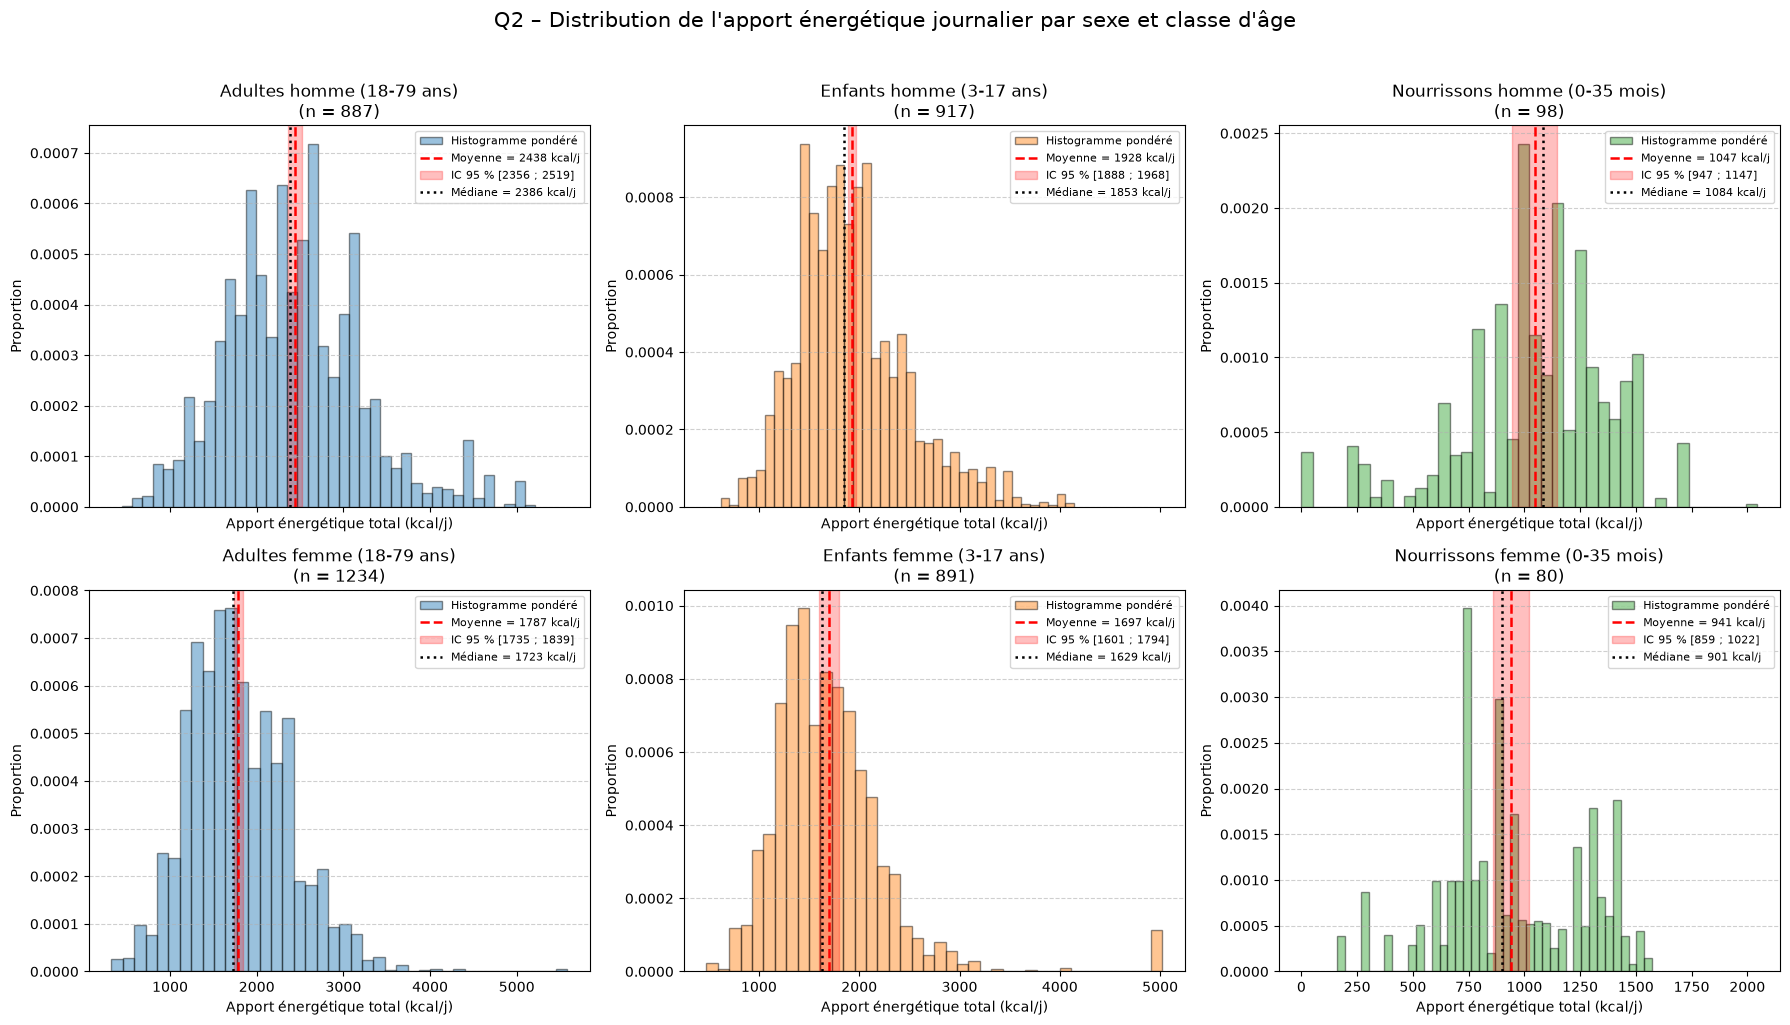

In [20]:
# Ordre souhaité : hommes sur la 1re ligne, femmes sur la 2e
ordre_groupes = [
    "Adultes homme (18-79 ans)",
    "Enfants homme (3-17 ans)",
    "Nourrissons homme (0-35 mois)",
    "Adultes femme (18-79 ans)",
    "Enfants femme (3-17 ans)",
    "Nourrissons femme (0-35 mois)",
]

# Créer une figure de 2 lignes x 3 colonnes
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10),
    sharex="col"  # Même échelle X pour hommes/femmes d'une même classe d'âge
)

for i, nom in enumerate(ordre_groupes):
    ligne = 0 if "homme" in nom else 1
    colonne = (
        0 if nom.startswith("Adultes")
        else 1 if nom.startswith("Enfants")
        else 2
    )
    ax = axes[ligne, colonne]

    d, pond, couleur = groupes_q2[nom]
    d = d.dropna(subset=[VAR_E, pond])
    d = d[d[pond] > 0]

    y = d[VAR_E].to_numpy(float)
    w = d[pond].to_numpy(float)

    # Histogramme pondéré
    ax.hist(
        y, bins=40, weights=w, density=True,
        color=couleur, alpha=0.45, edgecolor="black",
        label="Histogramme pondéré"
    )

    # Statistiques correspondantes
    s = tableau_q2.loc[nom]

    ax.axvline(
        s["Moyenne"], color="red", ls="--", lw=1.8,
        label=f"Moyenne = {s['Moyenne']:.0f} kcal/j"
    )

    ax.axvspan(
        s["IC95% inf"], s["IC95% sup"],
        color="red", alpha=0.25,
        label=f"IC 95 % [{s['IC95% inf']:.0f} ; {s['IC95% sup']:.0f}]"
    )

    ax.axvline(
        s["Médiane"], color="black", ls=":", lw=1.8,
        label=f"Médiane = {s['Médiane']:.0f} kcal/j"
    )

    ax.set_title(f"{nom}\n(n = {int(s['n (non pondéré)'])})")
    ax.set_xlabel("Apport énergétique total (kcal/j)")
    ax.set_ylabel("Proportion")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(fontsize=8)

fig.suptitle(
    "Q2 – Distribution de l'apport énergétique journalier par sexe et classe d'âge",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()


Les apports énergétiques journaliers moyens sont globalement plus élevés chez les hommes que chez les femmes, avec un écart marqué chez les adultes (2 439 contre 1 793 kcal/j) et plus modéré chez les enfants (1 941 contre 1 718 kcal/j). Chez les nourrissons, les moyennes sont proches (1 126 kcal/j chez les garçons contre 1 045 kcal/j chez les filles), mais les distributions sont plus dispersées et les effectifs plus faibles. IL est probable que pour les nourissons, la différence alimenatire du à l'âge soit plus impactant que les différences de sexe.

**Q3 — Âge :**
Comment évoluent les apports nutritionnels avec l'âge ?  

Cette fois ci on sépare les populations en tranche d'âge.  
Rappel : 
- Adulte : "tage_PS" entre 7 et 9
- Enfant : "tage_PS" entre 3 et 6
- Nourisson : "tage_PS" entre 1 et 2


In [21]:
df_ad_7 = df_adulte[df_adulte['tage_PS'] == 7].copy()
df_ad_8 = df_adulte[df_adulte['tage_PS'] == 8].copy()
df_ad_9 = df_adulte[df_adulte['tage_PS'] == 9].copy()
df_en_3 = df_enfant[df_enfant['tage_PS'] == 3].copy()
df_en_4 = df_enfant[df_enfant['tage_PS'] == 4].copy()
df_en_5 = df_enfant[df_enfant['tage_PS'] == 5].copy()
df_en_6 = df_enfant[df_enfant['tage_PS'] == 6].copy()
df_nr_1 = df_nourisson[df_nourisson['tage_PS'] == 1].copy()
df_nr_2 = df_nourisson[df_nourisson['tage_PS'] == 2].copy()


groupes_q3 = {
    "Nourrissons (0-11 mois)":  (df_nr_1, "pond_indiv_enf_pop3", "tab:green"),
    "Nourrissons (1-3 ans)":  (df_nr_2, "pond_indiv_enf_pop3", "tab:green"),
    "Enfants (4-6 ans)":       (df_en_3,    "pond_indiv_enf_pop3", "tab:orange"),
    "Enfants (7-10 ans)":       (df_en_4,    "pond_indiv_enf_pop3", "tab:orange"),
    "Enfants (11-14 ans)":       (df_en_5,    "pond_indiv_enf_pop3", "tab:orange"),
    "Enfants (15-17 ans)":       (df_en_6,    "pond_indiv_enf_pop3", "tab:orange"),
    "Adultes (18-44 ans)":      (df_ad_7,    "pond_indiv_adu_pop3", "tab:blue"),
    "Adultes (45-64 ans)":      (df_ad_8,    "pond_indiv_adu_pop3", "tab:blue"),
    "Adultes (65-79 ans)":      (df_ad_9,    "pond_indiv_adu_pop3", "tab:blue"),
}

tableau_q3 = pd.DataFrame({
    nom: stats_descriptives_ponderees(d, VAR_E, pond)
    for nom, (d, pond, _) in groupes_q3.items()
}).T
print("Apport énergétique journalier (kcal/j) – statistiques pondérées")
display(tableau_q3.round(1))

Apport énergétique journalier (kcal/j) – statistiques pondérées


,n (non pondéré),Moyenne,IC95% inf,IC95% sup,Écart-type,Min,Médiane,Max
Nourrissons (0-11 mois),52.0,637.1,543.0,731.2,278.4,0.0,683.9,1189.0
Nourrissons (1-3 ans),126.0,1122.1,1055.5,1188.7,248.4,585.4,1120.2,2044.4
Enfants (4-6 ans),345.0,1525.2,1479.2,1571.1,352.9,769.3,1479.7,3401.3
Enfants (7-10 ans),481.0,1829.6,1772.5,1886.7,415.8,914.2,1801.7,3598.6
Enfants (11-14 ans),543.0,2035.6,1889.9,2181.2,683.3,634.5,1934.4,5020.7
Enfants (15-17 ans),406.0,1888.5,1798.0,1978.9,686.0,476.3,1824.4,4143.3
Adultes (18-44 ans),783.0,2190.4,2104.1,2276.6,800.8,323.1,2075.7,5582.4
Adultes (45-64 ans),827.0,2089.4,1995.1,2183.7,735.2,539.2,1978.1,5060.8
Adultes (65-79 ans),511.0,1899.7,1828.2,1971.2,682.0,326.2,1791.7,4983.0


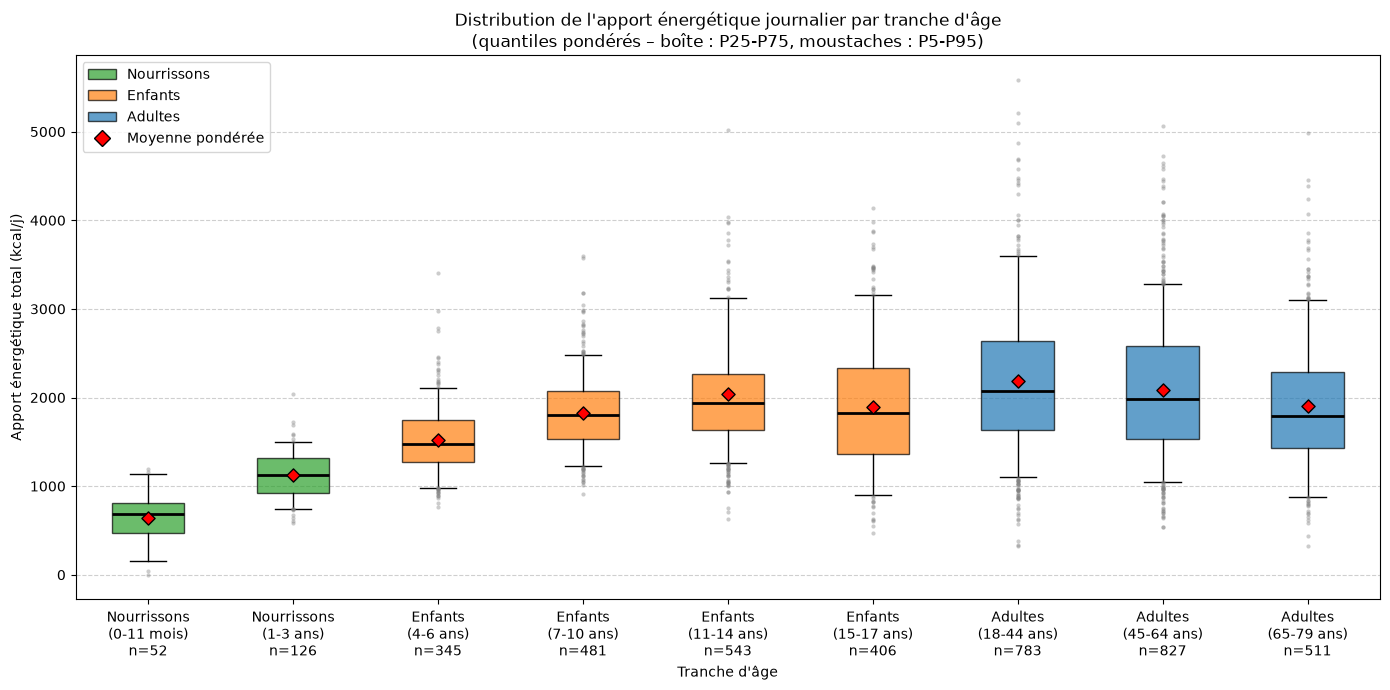

In [22]:
boites, couleurs_b = [], []

for nom, (d, pond, couleur) in groupes_q3.items():
    d = d.dropna(subset=[VAR_E, pond])
    d = d[d[pond] > 0]
    y, w = d[VAR_E].to_numpy(float), d[pond].to_numpy(float)
    p5, p25, med, p75, p95 = quantile_pondere(y, w, [0.05, 0.25, 0.5, 0.75, 0.95])

    categorie, tranche = nom.split(" (")
    boites.append({
        "label": f"{categorie}\n({tranche}\nn={len(d)}",
        "whislo": p5, "q1": p25, "med": med, "q3": p75, "whishi": p95,
        "fliers": y[(y < p5) | (y > p95)],
    })
    couleurs_b.append(couleur)

fig, ax = plt.subplots(figsize=(14, 7))

bp = ax.bxp(boites, patch_artist=True, showfliers=True,
            boxprops={"edgecolor": "black"},
            medianprops={"color": "black", "lw": 2},
            whiskerprops={"color": "black"},
            capprops={"color": "black"},
            flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "grey", "markeredgecolor": "none", "alpha": 0.4})

for patch, c in zip(bp["boxes"], couleurs_b):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)


ax.scatter(np.arange(1, len(tableau_q3) + 1), tableau_q3["Moyenne"],
           marker="D", color="red", edgecolor="black", zorder=5, s=45)

ax.set_xlabel("Tranche d'âge")
ax.set_ylabel("Apport énergétique total (kcal/j)")
ax.set_title("Distribution de l'apport énergétique journalier par tranche d'âge\n"
             "(quantiles pondérés – boîte : P25-P75, moustaches : P5-P95)")
ax.grid(axis="y", linestyle="--", alpha=0.6)

handles = [Patch(facecolor="tab:green",  edgecolor="black", alpha=0.7, label="Nourrissons"),
           Patch(facecolor="tab:orange", edgecolor="black", alpha=0.7, label="Enfants"),
           Patch(facecolor="tab:blue",   edgecolor="black", alpha=0.7, label="Adultes"),
           Line2D([0], [0], marker="D", color="w", markerfacecolor="red",
                  markeredgecolor="black", markersize=8, label="Moyenne pondérée")]
ax.legend(handles=handles, loc="upper left")

plt.tight_layout()
plt.show()

La moyenne des apports énergétiques journaliers augmentent globalement avec l’âge, passant d’environ 650 kcal/j chez les nourrissons de 0 à 11 mois à plus de 2 000 kcal/j chez les adultes de 18 à 44 ans. Ils progressent durant l’enfance, atteignent un plateau au début de l’âge adulte, puis diminuent progressivement chez les adultes plus âgés. Enfin, la dispersion des apports s’accentue avec l’âge, notamment chez les adultes, ce qui traduit une plus grande hétérogénéité des consommations énergétiques au sein de ces groupes.

**Q4 — Densité nutritionnelle :**
Comment comparer les apports nutritionnels à énergie comparable ?  

Les apports bruts (g/j, mg/j, µg/j) dépendent fortement de la quantité totale mangée : un adolescent qui consomme 3000 kcal/j aura mécaniquement des apports plus élevés qu’une personne âgée à 1700 kcal/j, sans que son alimentation soit pour autant de meilleure qualité. Pour s’affranchir de cet effet, il faut calculer pour chaque nutriment sa densité nutritionnelle, c’est-à-dire en apport pour 1000 kcal.

Pour chaque individu, on calcule le rapport 1000 × nutriment_X / nutriment1 (nutriment1 étant l’apport énergétique total en kcal/j), dont l’unité est celle du nutriment par 1000 kcal. Ce rapport est calculé à l’échelle individuelle, puis agrégé par une moyenne pondérée (pond_indiv_adu_pop3 pour les adultes, pond_indiv_enf_pop3 pour les enfants et les nourrissons), avec un IC 95 % tenant compte du plan de sondage (strates et ZAE). Calculer le rapport avant la moyenne permet d’obtenir la densité moyenne d’un individu du groupe, plutôt que le rapport entre deux moyennes.

Les groupes (adultes, enfants, nourrissons) sont traités séparément, conformément à la notice INCA3. Les résultats sont présentés en diagrammes en barres (moyenne et IC 95 %), un par ensemble de nutriments (nutriments de base, minéraux, vitamines), afin de ne pas mélanger des unités différentes. Pour les vitamines, une double échelle est utilisée (C et E en mg, D en µg).

In [23]:
groupe_q4 = {
    "Adultes (18-79 ans)":      (df_adulte,    "pond_indiv_adu_pop3", "tab:blue"),
    "Enfants (3-17 ans)":       (df_enfant,    "pond_indiv_enf_pop3", "tab:orange"),
    "Nourrissons (0-35 mois)":  (df_nourisson, "pond_indiv_enf_pop3", "tab:green"),
}

dic_nutriments = {
    # Nutriments de base
    "nutriment3": "Protéines (g/j)",
    "nutriment4": "Glucides (g/j)",
    "nutriment5": "Sucres (g/j)",
    "nutriment6": "Amidon (g/j)",
    "nutriment8": "Fibres (g/j)",
    "nutriment10": "Lipides (g/j)",
    "nutriment11": "Acides gras saturés (AGS) (g/j)",
    # Minéraux
    "nutriment30": "Sodium (mg/j)",
    "nutriment32": "Magnésium (mg/j)",
    "nutriment33": "Phosphore (mg/j)",
    "nutriment34": "Potassium (mg/j)",
    "nutriment35": "Calcium (mg/j)",
    # Vitamines
    "nutriment51": "Vitamine C (mg/j)",
    "nutriment52": "Vitamine D (μg/j)",
    "nutriment53": "Vitamine E (mg/j)"
}

for nom, (d, pond, couleur) in groupe_q4.items():
    for nut in dic_nutriments : 
        d[f'rap_{nut}'] = d[nut] * 1000 / d[VAR_E]


# ---------- Moyenne pondérée + IC 95 % de chaque rapport, par groupe ----------
resultats = {}   # (groupe, nut) -> (moy, ic_inf, ic_sup)
for g, (d, pond, _) in groupe_q4.items():
    for nut in dic_nutriments:
        var = f"rap_{nut}"
        dd = d.dropna(subset=[var, pond, "strate", "zae"])
        dd = dd[(dd[pond] > 0) & np.isfinite(dd[var])]
        moy, se, lo, hi = ic95_moyenne_plan_sondage(dd, var, pond)
        resultats[(g, nut)] = (moy, lo, hi)

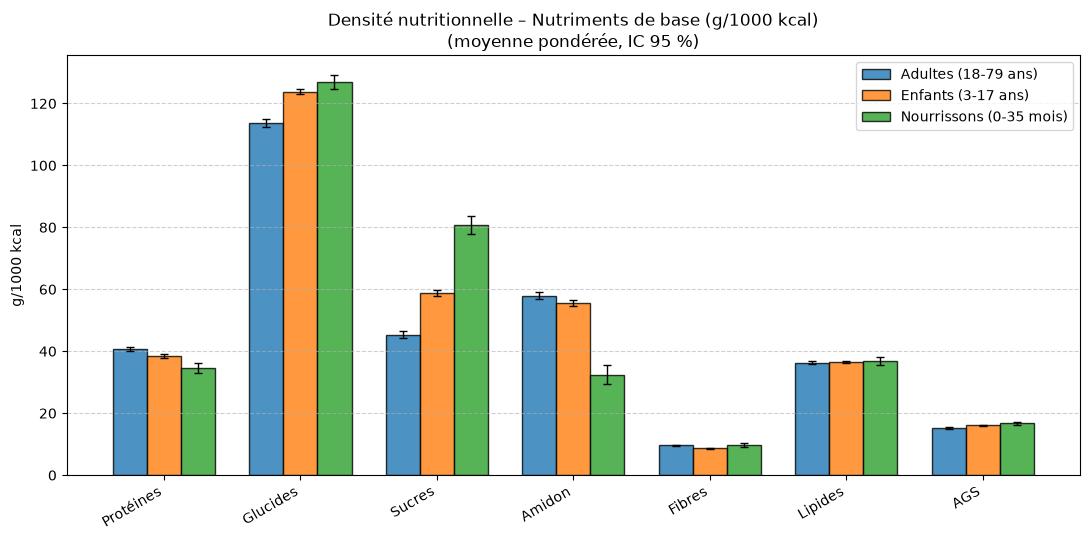

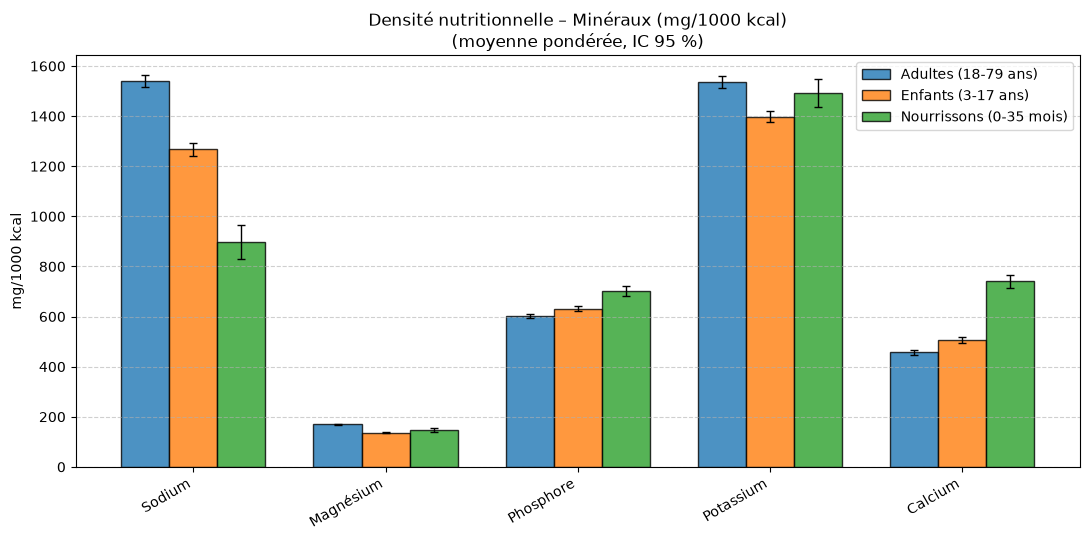

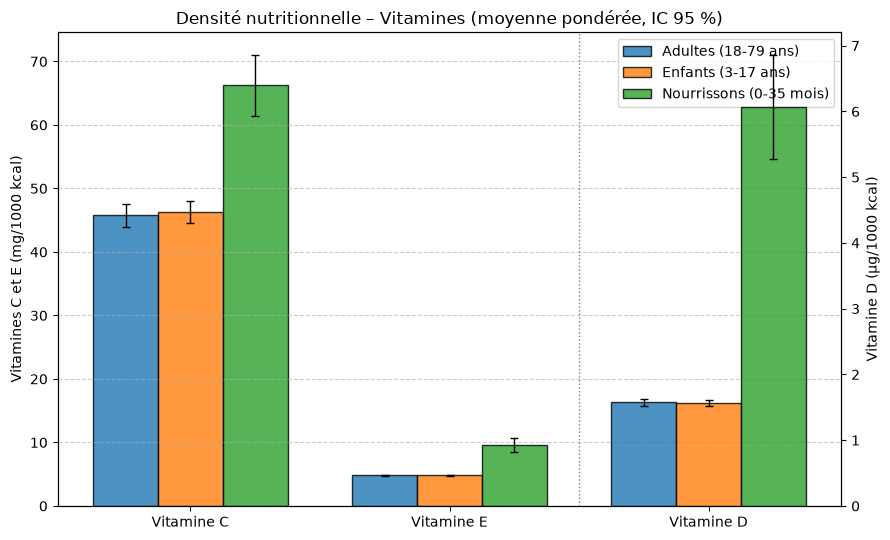

In [24]:
ensembles = {
    "Nutriments de base (g/1000 kcal)": ["nutriment3", "nutriment4", "nutriment5", "nutriment6",
                                          "nutriment8", "nutriment10", "nutriment11"],
    "Minéraux (mg/1000 kcal)":          ["nutriment30", "nutriment32", "nutriment33",
                                          "nutriment34", "nutriment35"],
    "Vitamines":                        ["nutriment51", "nutriment53", "nutriment52"],  # C, E (mg) | D (µg)
}

def nom_court(nut):
    return dic_nutriments[nut].split(" (")[0] if "AGS" not in dic_nutriments[nut] else "AGS"


# ---------- Fonction de tracé d'une série de barres ----------
def barres(ax, nuts, decalage_x=0, largeur=0.25, n_total=None):
    n_total = n_total or len(nuts)
    for i, (g, (_, _, couleur)) in enumerate(groupe_q4.items()):
        m  = np.array([resultats[(g, n)][0] for n in nuts])
        lo = np.array([resultats[(g, n)][1] for n in nuts])
        hi = np.array([resultats[(g, n)][2] for n in nuts])
        x = decalage_x + np.arange(len(nuts)) + (i - 1) * largeur
        ax.bar(x, m, width=largeur, color=couleur, edgecolor="black", alpha=0.8,
               yerr=[m - lo, hi - m], capsize=3, error_kw={"elinewidth": 1})

legende = [Patch(facecolor=c, edgecolor="black", alpha=0.8, label=g)
           for g, (_, _, c) in groupe_q4.items()]

# ---------- Figures 1 et 2 : base et minéraux  ----------
for titre in list(ensembles)[:2]:
    nuts = ensembles[titre]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    barres(ax, nuts)
    ax.set_xticks(np.arange(len(nuts)))
    ax.set_xticklabels([nom_court(n) for n in nuts], rotation=30, ha="right")
    ax.set_ylabel(titre.split("(")[1].rstrip(")"))
    ax.set_title(f"Densité nutritionnelle – {titre}\n(moyenne pondérée, IC 95 %)")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(handles=legende)
    plt.tight_layout()
    plt.show()

# ---------- Figure 3 : vitamines ----------
vit_mg, vit_ug = ["nutriment51", "nutriment53"], ["nutriment52"]
fig, ax1 = plt.subplots(figsize=(9, 5.5))
ax2 = ax1.twinx()

barres(ax1, vit_mg, decalage_x=0)    # C, E
barres(ax2, vit_ug, decalage_x=2)    # D

ax1.set_xticks([0, 1, 2])
ax1.set_xticklabels([nom_court(n) for n in vit_mg + vit_ug])
ax1.set_ylabel("Vitamines C et E (mg/1000 kcal)")
ax2.set_ylabel("Vitamine D (µg/1000 kcal)")
ax1.axvline(1.5, color="grey", ls=":", lw=1)
ax1.set_title("Densité nutritionnelle – Vitamines (moyenne pondérée, IC 95 %)")
ax1.grid(axis="y", linestyle="--", alpha=0.6)
ax1.legend(handles=legende, loc="upper right")
plt.tight_layout()
plt.show()

Les glucides et les sucres sont plus élevés chez les enfants et les nourrissons que chez les adultes. Cela pourrait s’expliquer par la présence de lactose dans le lait maternel ou infantile piour les nourrissons. Les autres nutriments présentent des différences relativement faibles.     
Les adultes présentent une densité en sodium plus élevée potentiellement lié à une consommation plus importante d’aliments transformés. Le calcium est particulièrement élevé chez les nourrissons, probablement en raison de la place importante du lait dans leur alimentation et de leurs besoins liés à la croissance osseuse.    
Les nourrissons présentent des densités plus élevées en vitamines C, E et surtout D. Cela peut s’expliquer par la composition de leur alimentation et par une éventuelle supplémentation en vitamine D.

**Q5 — Contributeurs :**
Quels sont les principaux aliments contribuant aux apports en protéines ?  
 --> Répéter l’analyse pour : calcium ; fer ; fibres ; vitamine C


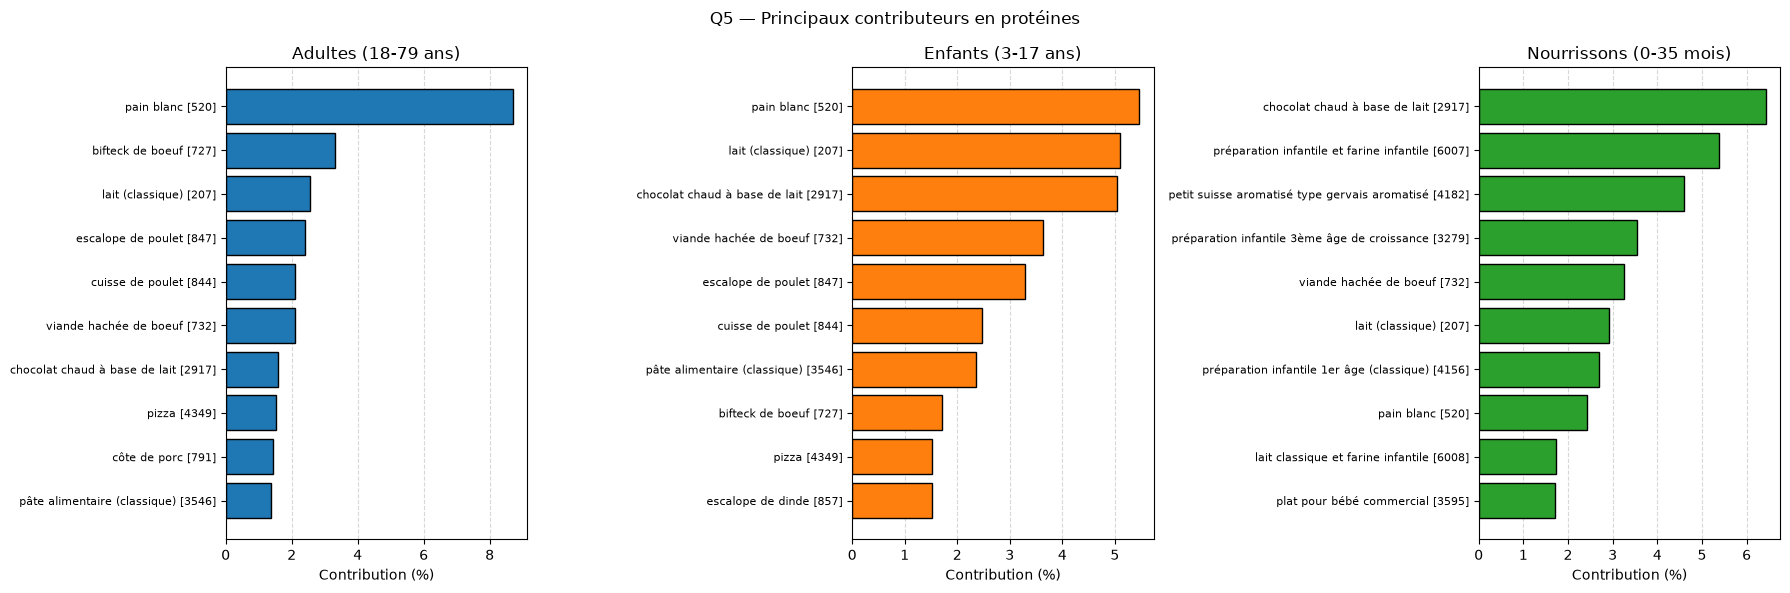

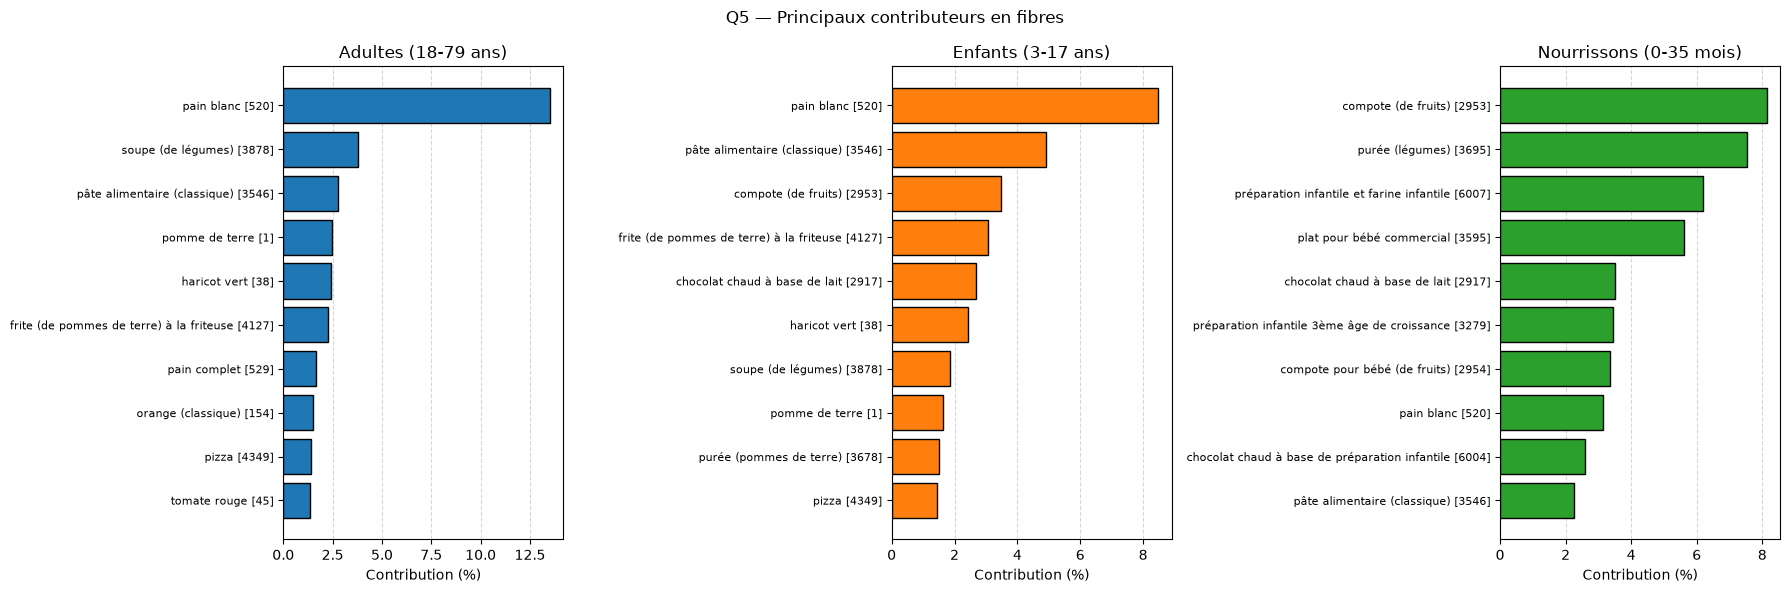

In [25]:
# ---------- Q5 — Principaux aliments contributeurs ----------

NUTRIMENTS_Q5 = {"proteines": "Protéines", "calcium": "Calcium", "fer": "Fer", "fibres": "Fibres", "vitamine_c": "Vitamine C"}
NUTRIMENTS_A_AFFICHER = ["protéines", "fibres"]  # Choisir ici les nutriments

nuts = {k: v for n in NUTRIMENTS_A_AFFICHER for k, v in NUTRIMENTS_Q5.items() if v.casefold() == n.casefold()}
assert len(nuts) == len(NUTRIMENTS_A_AFFICHER), "Nutriment inconnu dans NUTRIMENTS_A_AFFICHER"

groupes_q5 = {
    "Adultes (18-79 ans)": (df_adulte, "pond_indiv_adu_pop3", "tab:blue"),
    "Enfants (3-17 ans)": (df_enfant, "pond_indiv_enf_pop3", "tab:orange"),
    "Nourrissons (0-35 mois)": (df_nourisson, "pond_indiv_enf_pop3", "tab:green")
}

# Charger les données et les pondérations individuelles
cols = ["NOIND", "R24_num", "R24_pond", "qte_conso", "aliment_code_INCA3", "aliment_libelle_INCA3", *nuts]
d = pd.read_csv("tables/conso-compo-alim-vf-mad-datagouv2021.csv", sep=";", usecols=cols)

poids = pd.concat([
    data[["NOIND", pond]].rename(columns={pond: "poids"}).assign(groupe=g)
    for g, (data, pond, _) in groupes_q5.items()
], ignore_index=True).drop_duplicates("NOIND")

for x in [d, poids]:
    x["NOIND"] = x["NOIND"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)

d = d.merge(poids, on="NOIND", how="inner", validate="many_to_one")

# Pondérer les jours de rappel
jours = d[["NOIND", "R24_num", "R24_pond"]].drop_duplicates(["NOIND", "R24_num"])
jours["poids_jour"] = jours["R24_pond"] / jours.groupby("NOIND")["R24_pond"].transform("sum")
d = d.merge(jours[["NOIND", "R24_num", "poids_jour"]], on=["NOIND", "R24_num"], validate="many_to_one")

# Calculer les contributions nutritionnelles pondérées
d["aliment"] = d["aliment_libelle_INCA3"].fillna("Libellé manquant").astype(str) + " [" + d["aliment_code_INCA3"].astype(str) + "]"
for c in ["qte_conso", *nuts]:
    d[c] = pd.to_numeric(d[c], errors="coerce")

d[list(nuts)] = d[list(nuts)].mul(d["qte_conso"], axis=0).div(100).mul(d["poids_jour"] * d["poids"], axis=0)
contrib = d.groupby(["groupe", "aliment"])[list(nuts)].sum().reset_index()
parts = contrib.copy()
parts[list(nuts)] = contrib[list(nuts)].div(contrib.groupby("groupe")[list(nuts)].transform("sum"), axis=0) * 100

# Un graphique par nutriment, avec les trois groupes côte à côte
for nut, nom in nuts.items():
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for ax, (groupe, (_, _, couleur)) in zip(axes, groupes_q5.items()):
        top = parts[parts["groupe"] == groupe].set_index("aliment")[nut].nlargest(10).sort_values()
        ax.barh(top.index, top.values, color=couleur, edgecolor="black")
        ax.set(title=groupe, xlabel="Contribution (%)")
        ax.tick_params(axis="y", labelsize=8)
        ax.grid(axis="x", linestyle="--", alpha=0.5)
        ax.set_axisbelow(True)

    fig.suptitle(f"Q5 — Principaux contributeurs en {nom.lower()}")
    plt.tight_layout()
    plt.show()

**Q6 — Variabilité :** Quelle est la variabilité interindividuelle des apports au sein d’un même groupe (par exemple chez les femmes 25 - 44 ans) ?  

,n (non pondéré),Moyenne,IC95% inf,IC95% sup,Écart-type,Min,Médiane,Max,Q1,Q3,Écart interquartile,CV (%)
Énergie (kcal/j),459.0,1859.67,1768.19,1951.15,596.94,323.15,1810.83,5582.39,1398.79,2237.75,838.96,32.10
Protéines (g/j),459.0,70.39,67.13,73.65,21.93,14.26,67.09,194.15,57.14,83.39,26.25,31.15
Calcium (mg/j),459.0,858.27,805.73,910.80,356.77,143.08,809.33,2408.11,592.23,1041.56,449.32,41.57
Fer (mg/j),459.0,9.10,8.65,9.56,3.24,1.83,8.85,29.82,6.82,10.94,4.12,35.63
Fibres (g/j),459.0,17.08,16.23,17.93,6.21,3.13,16.52,44.46,12.72,21.05,8.33,36.36
Vitamine C (mg/j),459.0,77.68,71.72,83.63,48.61,3.33,67.43,286.32,39.31,103.00,63.69,62.58


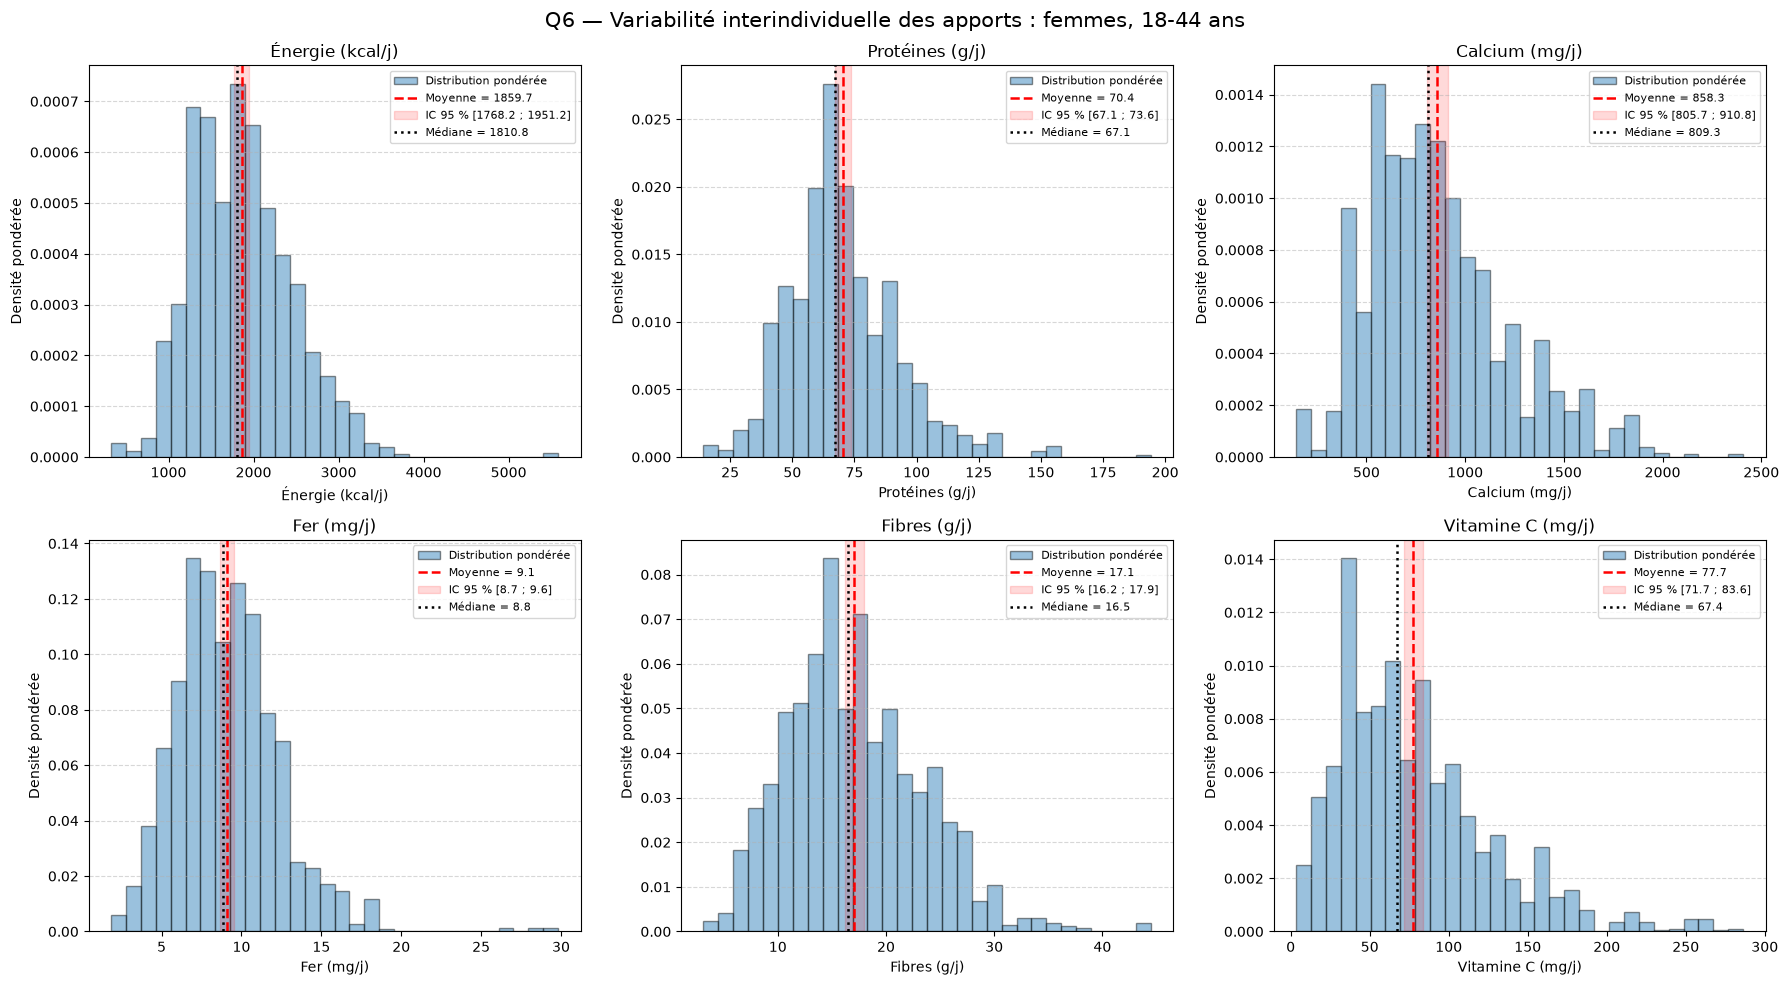

In [26]:
# ---------- Q6 — Variabilité interindividuelle par classe d'âge et sexe ----------

AGE_Q6 = 7   # Choisir une classe de 1 à 9
SEXE_Q6 = 2  # 1 = Homme ; 2 = Femme

NUTRIMENTS_Q6 = {
    "nutriment1": "Énergie (kcal/j)", "nutriment3": "Protéines (g/j)",
    "nutriment35": "Calcium (mg/j)", "nutriment37": "Fer (mg/j)",
    "nutriment8": "Fibres (g/j)", "nutriment51": "Vitamine C (mg/j)"
}

classes_age_q6 = {
    1: (df_nr_1, "0-11 mois", "pond_indiv_enf_pop3", "tab:green"),
    2: (df_nr_2, "1-3 ans", "pond_indiv_enf_pop3", "tab:green"),
    3: (df_en_3, "4-6 ans", "pond_indiv_enf_pop3", "tab:orange"),
    4: (df_en_4, "7-10 ans", "pond_indiv_enf_pop3", "tab:orange"),
    5: (df_en_5, "11-14 ans", "pond_indiv_enf_pop3", "tab:orange"),
    6: (df_en_6, "15-17 ans", "pond_indiv_enf_pop3", "tab:orange"),
    7: (df_ad_7, "18-44 ans", "pond_indiv_adu_pop3", "tab:blue"),
    8: (df_ad_8, "45-64 ans", "pond_indiv_adu_pop3", "tab:blue"),
    9: (df_ad_9, "65-79 ans", "pond_indiv_adu_pop3", "tab:blue")
}

data_age, nom_age, pond, couleur = classes_age_q6[AGE_Q6]
nom_sexe = {1: "hommes", 2: "femmes"}[SEXE_Q6]
d_q6 = data_age[data_age["sex_PS"] == SEXE_Q6].copy()

# Statistiques descriptives pondérées
resultats_q6 = {}

for nut, nom in NUTRIMENTS_Q6.items():
    d = d_q6.dropna(subset=[nut, pond, "strate", "zae"])
    d = d[(d[pond] > 0) & np.isfinite(d[nut])]

    if d.empty:
        continue

    y, w = d[nut].to_numpy(float), d[pond].to_numpy(float)
    s = stats_descriptives_ponderees(d, nut, pond)
    q1, q3 = quantile_pondere(y, w, [0.25, 0.75])

    s.update({
        "Q1": q1,
        "Q3": q3,
        "Écart interquartile": q3 - q1,
        "CV (%)": 100 * s["Écart-type"] / s["Moyenne"]
                  if s["Moyenne"] != 0 else np.nan
    })
    resultats_q6[nom] = s

tableau_q6 = pd.DataFrame(resultats_q6).T
display(tableau_q6.round(2))

# Histogrammes : 6 nutriments, disposés sur 2 lignes et 3 colonnes
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (nut, nom) in zip(axes.flat, NUTRIMENTS_Q6.items()):
    d = d_q6.dropna(subset=[nut, pond, "strate", "zae"])
    d = d[(d[pond] > 0) & np.isfinite(d[nut])]

    if d.empty:
        ax.set_visible(False)
        continue

    y, w = d[nut].to_numpy(float), d[pond].to_numpy(float)
    s = resultats_q6[nom]

    ax.hist(y, bins=30, weights=w, density=True,
            color=couleur, alpha=0.45, edgecolor="black",
            label="Distribution pondérée")
    ax.axvline(s["Moyenne"], color="red", ls="--", lw=1.8,
               label=f"Moyenne = {s['Moyenne']:.1f}")
    ax.axvspan(s["IC95% inf"], s["IC95% sup"],
               color="red", alpha=0.15,
               label=f"IC 95 % [{s['IC95% inf']:.1f} ; {s['IC95% sup']:.1f}]")
    ax.axvline(s["Médiane"], color="black", ls=":", lw=1.8,
               label=f"Médiane = {s['Médiane']:.1f}")

    ax.set(title=nom, xlabel=nom, ylabel="Densité pondérée")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.legend(fontsize=8)

fig.suptitle(
    f"Q6 — Variabilité interindividuelle des apports : {nom_sexe}, {nom_age}",
    fontsize=15
)
plt.tight_layout()
plt.show()

D'après les données présentées pour les femmes de 18 à 44 ans, la variabilité interindividuelle des apports au sein de ce groupe se traduit par des distributions étendues. Il existe d'importantes différences de consommation d'un individu à un autre au sein d'une même population cible.

**Questions bonus**

Pour aller plus loin (niveau bonus)

1. Profils alimentaires (Q_Profils_alimentaires)  
Existe-t-il des profils alimentaires distincts (par exemple, une alimentation riche en produits sucrés ou en produits végétaux) ?

2. Diversité alimentaire (Q_Divers)  
Les personnes ayant une consommation énergétique élevée ont-elles également une alimentation plus diversifiée ?

3. Comparabilité des enquêtes de consommation (Q_Comp_Conso)  
Comment comparer entre elles les enquêtes de consommation, compte tenu des différences de :  
population ;  
périodes d'enquête ;  
nomenclatures ;  
méthodes de collecte ;  
groupes d'âge ;  
définition des aliments.  

4. Évolution temporelle des habitudes alimentaires (Q_Evolution_Temporelle)  
Comment les habitudes alimentaires ont-elles évolué entre INCA 1, INCA 2 et INCA 3 (par exemple, en matière de consommation de fruits, de légumes et de poisson) ?

5. Mapping entre INCA et Ciqual (Q_Mapping_INCA_CIQUAL)  
Comment automatiser la mise en correspondance (mapping) entre les aliments de l'enquête et les aliments de la base Ciqual ?